In [3]:
from scipy.stats import norm  # For normal distribution CDF (phi function)
import math
import numpy as np

In [3]:
phi_z = 0.6125
abs(norm.ppf(phi_z))

np.float64(0.2858408748811657)

In [7]:
def log2_map_from_tanh(norm_value, min_val, max_val):
    norm_01 = (norm_value + 1.0) / 2.0
    log_min = math.log2(min_val)
    log_max = math.log2(max_val)
    log_val = log_min + norm_01 * (log_max - log_min)
    return 2 ** log_val

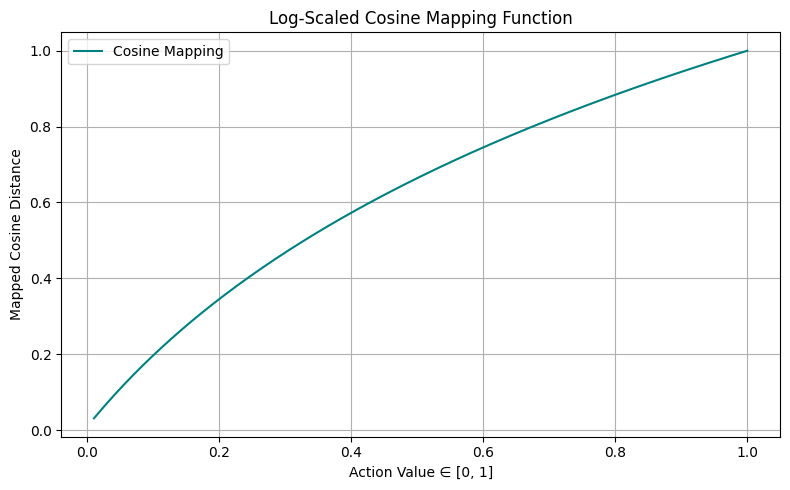

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def cosine_mapping_from_0_to_1(action_val, max_val=1.0, log_base=4.0, start_at=0.01):
    """
    Maps action ∈ [0, 1] to cosine distance ∈ [start_at, max_val]
    - action = 0 → start_at (very small constraint)
    - action = 1 → max_val
    - log-scaled growth
    """
    action = float(torch.clamp(torch.tensor(action_val), 0.0, 1.0))
    scaled = np.log1p(action * (log_base - 1)) / np.log(log_base)  # ∈ [0, 1]
    return start_at + (max_val - start_at) * scaled

# Generate input values in [0, 1]
x_vals = np.linspace(0.01, 1, 200)
y_vals = [cosine_mapping_from_0_to_1(x) for x in x_vals]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label='Cosine Mapping', color='teal')
plt.xlabel("Action Value ∈ [0, 1]")
plt.ylabel("Mapped Cosine Distance")
plt.title("Log-Scaled Cosine Mapping Function")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [3]:
N=9
action_space = [ 
    [x, y] for x in np.linspace(-1, 1, N) for y in np.linspace(-1, 1, N)
]

In [6]:
np.linspace(-1, 1, 9)

array([-1.  , -0.75, -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ])